In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import layers, models

In [2]:
axle_list = np.array(["Car1_Axle1.fit", "Car1_Axle2.fit", "Car1_Axle3.fit", "Car1_Axle4.fit", "Car2_Axle1.fit", "Car2_Axle2.fit", "Car2_Axle3.fit", "Car2_Axle4.fit", "Car3_Axle1.fit", "Car3_Axle2.fit", "Car3_Axle3.fit", "Car3_Axle4.fit", "Car4_Axle1.fit", "Car4_Axle2.fit", "Car4_Axle3.fit", "Car4_Axle4.fit", "Car5_Axle1.fit", "Car5_Axle2.fit", "Car5_Axle3.fit", "Car5_Axle4.fit", "Car6_Axle1.fit", "Car6_Axle2.fit", "Car6_Axle3.fit", "Car6_Axle4.fit", "Car7_Axle1.fit", "Car7_Axle2.fit", "Car7_Axle3.fit", "Car7_Axle4.fit", "Car8_Axle1.fit", "Car8_Axle2.fit", "Car8_Axle3.fit", "Car8_Axle4.fit", "Car9_Axle1.fit", "Car9_Axle2.fit", "Car9_Axle3.fit", "Car9_Axle4.fit", "Car10_Axle1.fit", "Car10_Axle2.fit", "Car10_Axle3.fit", "Car10_Axle4.fit", "Car11_Axle1.fit", "Car11_Axle2.fit", "Car11_Axle3.fit", "Car11_Axle4.fit", "Car12_Axle1.fit", "Car12_Axle2.fit", "Car12_Axle3.fit", "Car12_Axle4.fit", "Car13_Axle1.fit", "Car13_Axle2.fit", "Car13_Axle3.fit", "Car13_Axle4.fit", "Car14_Axle1.fit", "Car14_Axle2.fit", "Car14_Axle3.fit", "Car14_Axle4.fit"])
axle_count = len(axle_list)
axle_count

56

In [3]:
xs = []
ys = []

for axle in axle_list:
    df = pd.read_csv(axle, skiprows = 3)
    cap = len(df)
    xstep = []
    ystep = []
    
    for i in range(cap - 2):
        step = df.iloc[i].str.split().tolist()[0]
        if (len(step) > 1) & (step[0] != "!"):
            xstep.append(float(step[0]))
            ystep.append(float(step[1]))

    xs.append(xstep)
    ys.append(ystep)


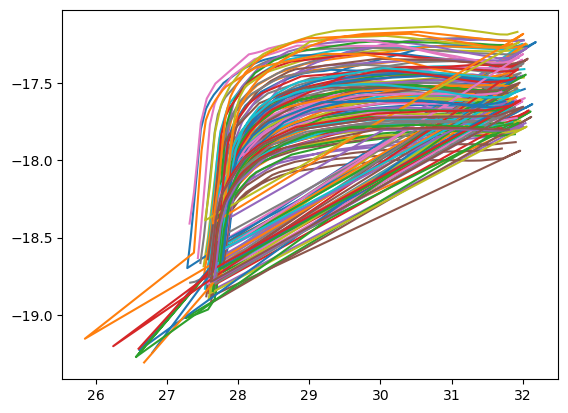

In [4]:
naxl = len(xs)

for i in range(naxl):
    plt.plot(xs[i], ys[i])

In [5]:
xs = []
ys = []

for axle in axle_list:
    df = pd.read_csv(axle, skiprows = 3)
    cap = len(df)
    xstep = []
    ystep = []
    
    for i in range(cap - 2):
        step = df.iloc[i].str.split().tolist()[0]
        if len(step) <= 1:
            xs.append(xstep)
            xstep = []
            ys.append(ystep)
            ystep = []
        elif (step[0] != "!"):
            xstep.append(float(step[0]))
            ystep.append(float(step[1]))

    xs.append(xstep)
    ys.append(ystep)


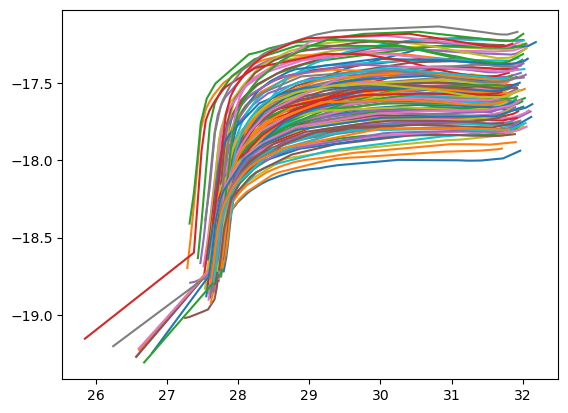

In [6]:
naxl = len(xs)

for i in range(naxl):
    plt.plot(xs[i], ys[i])

In [7]:
rxs = []
rys = []
lxs = []
lys = []

for axle in axle_list:
    df = pd.read_csv(axle, skiprows = 3)
    cap = len(df)
    xstep = []
    ystep = []
    side = "right"
    
    for i in range(cap - 2):
        step = df.iloc[i].str.split().tolist()[0]
        
        if len(step) == 1:
            side = "left" 
            rxs.append(xstep)
            rys.append(ystep)
            xstep = []
            ystep = []
        elif (side == "left"):
            xstep.append(float(step[0]))
            ystep.append(float(step[1]))
        elif (side == "right"):
            xstep.append(float(step[0]))
            ystep.append(float(step[1]))

    lxs.append(xstep)
    lys.append(ystep)

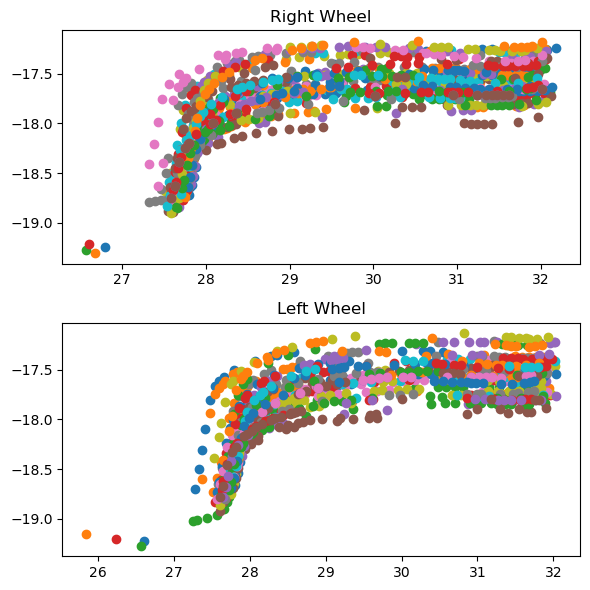

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(6, 6))

for i in range(axle_count):
    ax[0].scatter(rxs[i], rys[i])
    ax[0].set_title("Right Wheel")
    
    ax[1].scatter(lxs[i], lys[i])
    ax[1].set_title("Left Wheel")

plt.tight_layout()
plt.show()

In [9]:
fit_res = pd.read_excel("Eq_Con_Fit_Results.xlsm")

hunt_df = fit_res[["Filename", "Empty Axle from Lat Disp HS [mph]", "Loaded Axle from Lat Disp HS [mph]"]]
hunt_df = hunt_df[~hunt_df['Filename'].isin(["KRWHL_RProfile 1.wnt", "KRWHL_RProfile 2.wnt", "KRWHL_RProfile 3.wnt", "KRWHL_RProfile 4.wnt", "KRWHL_RProfile 5.wnt", "KRWHL_RProfile 6.wnt","KRWHL_RProfile 7.wnt"])]
hunt_df.reset_index(drop=True, inplace=True)

In [10]:
hunting_empty = []
hunting_full = []
ehunt = False
fhunt = False
step = 0

for i in range(len(hunt_df["Filename"])):
    if hunt_df["Empty Axle from Lat Disp HS [mph]"][i] != 80:
        ehunt = True

    if hunt_df["Loaded Axle from Lat Disp HS [mph]"][i] != 80:
        fhunt = True

    if step == 6:
        step = -1
        if ehunt == True:
            hunting_empty.append(True)
            ehunt = False
        else: 
            hunting_empty.append(False)

        if fhunt == True:
            hunting_full.append(True)
            fhunt = False
        else: 
            hunting_full.append(False)
    
    step += 1

y_empty_temp = [hunting_empty, hunting_empty]
y_empty = [item for sublist in y_empty_temp for item in sublist]

y_loaded_temp = [hunting_full, hunting_full]
y_loaded = [item for sublist in y_loaded_temp for item in sublist]

In [11]:
rlens = []
llens = []

for i in range(len(rxs)):
    rlens.append(len(rxs[i]))
    
for i in range(len(lxs)):
    llens.append(len(lxs[i]))

print(rlens, llens)

[19, 25, 26, 19, 19, 25, 22, 27, 22, 21, 24, 18, 23, 22, 21, 22, 26, 23, 19, 22, 26, 23, 23, 21, 28, 24, 16, 30, 31, 24, 24, 25, 19, 23, 25, 21, 22, 22, 21, 26, 26, 27, 23, 26, 26, 18, 27, 21, 27, 29, 24, 24, 22, 24, 17, 17] [23, 17, 20, 17, 21, 19, 25, 16, 18, 19, 18, 21, 28, 24, 26, 22, 16, 18, 19, 21, 26, 21, 17, 19, 25, 25, 24, 24, 24, 17, 20, 22, 22, 24, 18, 21, 19, 25, 26, 19, 22, 23, 22, 22, 23, 22, 23, 23, 20, 19, 23, 22, 19, 20, 18, 21]


In [12]:
rmean = np.mean(rlens) 
lmean = np.mean(llens) 
print(rmean, lmean, (rmean + lmean)/2)

23.160714285714285 21.214285714285715 22.1875


In [13]:
over_30 = [] 
ils = []
i = 0

for length in rlens:
    if length >= 29:
        over_30.append(length)
        ils.append(i)
    i += 1

print(over_30, ils)

[30, 31, 29] [27, 28, 49]


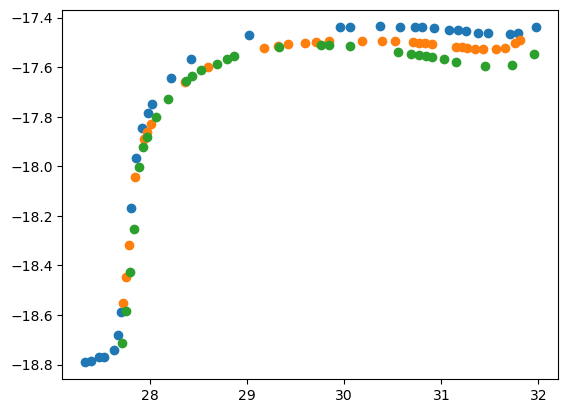

In [14]:
for i in ils:
    plt.scatter(rxs[i], rys[i])

In [15]:
rxs[ils[0]], rys[ils[0]] = rxs[ils[0]][2:over_30[0]], rys[ils[0]][2:over_30[0]]

endstep = len(rxs[ils[1]])
stepxs = rxs[ils[1]][0:endstep - 11] + rxs[ils[1]][endstep - 10:endstep - 8] + rxs[ils[1]][endstep-7:endstep-6] + rxs[ils[1]][endstep-5:endstep]
stepys = rys[ils[1]][0:endstep - 11] + rys[ils[1]][endstep - 10:endstep - 8] + rys[ils[1]][endstep-7:endstep-6] + rys[ils[1]][endstep-5:endstep]
rxs[ils[1]], rys[ils[1]] = stepxs, stepys

endstep2 = len(rxs[ils[2]])
stepxs2 = rxs[ils[2]][0:endstep2 - 7] + rxs[ils[2]][endstep2 - 6:endstep2]
stepys2 = rys[ils[2]][0:endstep2 - 7] + rys[ils[2]][endstep2 - 6:endstep2]
rxs[ils[2]], rys[ils[2]] = stepxs2, stepys2


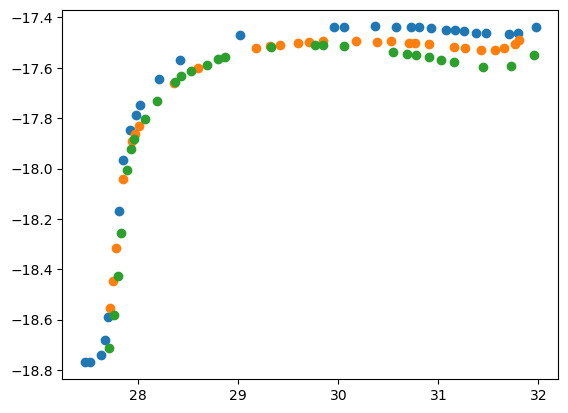

In [16]:
for i in ils:
    plt.scatter(rxs[i], rys[i])

In [17]:
print(len(rxs[ils[0]]), len(rxs[ils[1]]), len(rxs[ils[2]]))

28 28 28


In [18]:
for i in range(len(rxs)):
    rs = rxs[i]
    rsy = rys[i]
    ls = lxs[i]
    lsy = lys[i]
    
    while len(rs) != 28:
        whle = len(rs)
        frs, brs = rs[0:15], rs[15:whle]
        frsy, brsy = rsy[0:15], rsy[15:whle]
        rs = frs + [(frs[len(frs)-1] + brs[0])/2] + brs
        rsy = frsy + [(frsy[len(frsy)-1] + brsy[0])/2] + brsy
    rxs[i] = rs
    rys[i] = rsy
    
    while len(ls) != 28:
        whle = len(ls)
        fls, bls = ls[0:15], ls[15:whle]
        flsy, blsy = lsy[0:15], lsy[15:whle]
        ls = fls + [(fls[len(fls)-1] + bls[0])/2] + bls
        lsy = flsy + [(flsy[len(flsy)-1] + blsy[0])/2] + blsy
    lxs[i] = ls
    lys[i] = lsy


In [19]:
len(rys[5])

28

In [20]:
rlens = []
llens = []

for i in range(len(rxs)):
    rlens.append(len(rxs[i]))
    
for i in range(len(lxs)):
    llens.append(len(lxs[i]))

print(rlens, llens)

[28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28] [28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28]


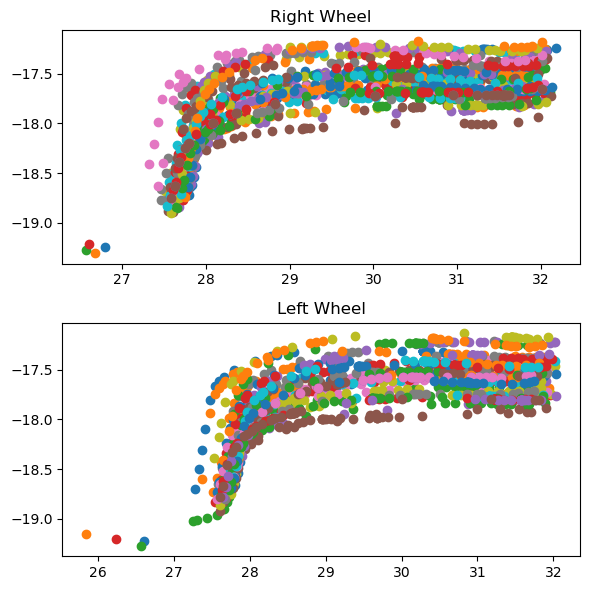

In [32]:
fig, ax = plt.subplots(2, 1, figsize=(6, 6))

for i in range(axle_count):
    ax[0].scatter(rxs[i], rys[i])
    ax[0].set_title("Right Wheel")
    
    ax[1].scatter(lxs[i], lys[i])
    ax[1].set_title("Left Wheel")

plt.tight_layout()
plt.show()

In [21]:
xr = []
xl = []
wheel = []

for i in range(axle_count):
    for j in range(len(rxs[i])):
        wheel.append([rxs[i][j], rys[i][j]])
    xr.append(wheel)
    wheel = []

for i in range(axle_count):
    for j in range(len(lxs[i])):
        wheel.append([lxs[i][j], lys[i][j]])
    xl.append(wheel)
    wheel = []

x = xr + xl
np.array(x).shape

(112, 28, 2)

In [22]:
x = np.array(x)
y_empty = np.array(y_empty)
y_loaded = np.array(y_loaded)

In [23]:
wheelnum = len(x)
coords = len(x[0])

xe_train, xe_test, ye_train, ye_test = train_test_split(x, y_empty, test_size = 25, random_state = 67)
xl_train, xl_test, yl_train, yl_test = train_test_split(x, y_loaded, test_size = 25, random_state = 67)

split_wn = len(xl_train)
print(wheelnum, coords, split_wn)

112 28 87


In [36]:
sum(y_empty == True)/len(y_empty)

np.float64(0.7857142857142857)

In [37]:
sum(y_loaded == True)/len(y_loaded)

np.float64(0.2857142857142857)

In [28]:
model = models.Sequential([
        layers.Input(shape=(28,2)),
        layers.LSTM(87, return_sequences=False),
        layers.Dropout(0.3),
        layers.Dense(28, activation="relu"),
        layers.Dense(1, activation="sigmoid"),])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                        │ (None, 87)                  │          31,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 87)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 28)                  │           2,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              29 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 33,813 (132.08 KB)

 Trainable params: 33,813 (132.08 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
model.fit(xe_train, ye_train, epochs=20, batch_size = split_wn, validation_split=0.2,)

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step - accuracy: 0.6957 - auc: 0.5948 - loss: 0.5922 - val_accuracy: 0.7778 - val_auc: 0.5000 - val_loss: 0.5658
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step - accuracy: 0.7826 - auc: 0.3851 - loss: 0.5913 - val_accuracy: 0.7778 - val_auc: 0.5000 - val_loss: 0.5413
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - accuracy: 0.7971 - auc: 0.4630 - loss: 0.5390 - val_accuracy: 0.7778 - val_auc: 0.5000 - val_loss: 0.5307
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 267ms/step - accuracy: 0.7971 - auc: 0.3903 - loss: 0.5364 - val_accuracy: 0.7778 - val_auc: 0.6250 - val_loss: 0.5305
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 328ms/step - accuracy: 0.7971 - auc: 0.5221 - loss: 0.5119 - val_accuracy: 0.7778 - val_auc: 0.5000 - val_loss: 0.5359
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 339ms/step - accuracy: 0.7971 - auc: 0.5201 - loss: 0.5132 - val_accuracy: 0.7778 - val_auc: 0.5000 - val_loss: 0.5432
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - acc

In [30]:
pred = model.predict(xe_train) > 0.5

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 270ms/step


In [31]:
pred

array([[ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [

In [33]:
model.fit(xl_train, yl_train, epochs=20, batch_size = split_wn, validation_split=0.2,)

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 566ms/step - accuracy: 0.2609 - auc: 0.3720 - loss: 1.2055 - val_accuracy: 0.3889 - val_auc: 0.5000 - val_loss: 0.9935
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step - accuracy: 0.2609 - auc: 0.5773 - loss: 1.1342 - val_accuracy: 0.3889 - val_auc: 0.5000 - val_loss: 0.9435
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step - accuracy: 0.2609 - auc: 0.5507 - loss: 1.0963 - val_accuracy: 0.3889 - val_auc: 0.5000 - val_loss: 0.8900
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 340ms/step - accuracy: 0.2609 - auc: 0.5588 - loss: 0.9827 - val_accuracy: 0.3889 - val_auc: 0.5000 - val_loss: 0.8350
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step - accuracy: 0.2609 - auc: 0.4798 - loss: 0.9438 - val_accuracy: 0.3889 - val_auc: 0.5000 - val_loss: 0.7833
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 323ms/step - accuracy: 0.2754 - auc: 0.5436 - loss: 0.8322 - val_accuracy: 0.3889 - val_auc: 0.7143 - val_loss: 0.7395
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step - 

In [112]:
pred = model.predict(xl_train) > 0.5
pred

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


array([[False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [

In [109]:
ye_test

array([ True,  True,  True, False,  True,  True,  True,  True,  True,
       False,  True,  True, False, False,  True,  True, False,  True,
       False,  True,  True,  True,  True,  True,  True])

In [114]:
model.fit(x, y_empty, epochs=20, batch_size = 28, validation_split=0.2,)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.2360 - auc: 0.4618 - loss: 1.1000 - val_accuracy: 0.1304 - val_auc: 0.5000 - val_loss: 1.0903
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.2360 - auc: 0.5158 - loss: 0.9787 - val_accuracy: 0.1304 - val_auc: 0.5000 - val_loss: 0.9713
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.2360 - auc: 0.5452 - loss: 0.8788 - val_accuracy: 0.1304 - val_auc: 0.5000 - val_loss: 0.8667
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.2472 - auc: 0.5007 - loss: 0.8055 - val_accuracy: 0.1304 - val_auc: 0.5000 - val_loss: 0.7834
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.3034 - auc: 0.5298 - loss: 0.7374 - val_accuracy: 0.1304 - val_auc: 0.5000 - val_loss: 0.7003
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.5393 - auc: 0.4160 - loss: 0.6921 - val_accuracy: 0.8696 - val_auc: 0.5000 - val_loss: 0.6173
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accur

In [117]:
pred = model.predict(xe_test) > 0.5
pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step


array([[ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True],
       [ True]])